In [1]:
import os
os.environ["THEANO_FLAGS"] = 'device=cuda0,floatX=float32,force_device=True'
import numpy as np
import pandas as pd
import scanpy as sc
import spapros as sp
import scipy.sparse as sparse
import scipy.io
import zipfile
import tempfile
import os
import gzip
import gc

import warnings
warnings.filterwarnings('ignore')

In [2]:
sc.settings.verbosity = 0
sc.logging.print_header()
print(f"spapros=={sp.__version__}")

2025-01-14 17:55:20.492220: I tensorflow/core/util/port.cc:110] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-01-14 17:55:22.818515: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2025-01-14 17:55:24.514739: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2025-01-14 17:55:24.515536: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-01-14 17:55:39.368394: W tensorflow/compiler/tf2t

scanpy==1.9.3 anndata==0.8.0 umap==0.5.3 numpy==1.23.0 scipy==1.11.0 pandas==1.4.3 scikit-learn==1.1.3 statsmodels==0.13.2 python-igraph==0.11.6 louvain==0.7.1 pynndescent==0.5.7
spapros==0.1.4


In [3]:
biopsy = sc.read_h5ad("./kidney_atlas/scVI_kidney_biopsy_KPMP.h5ad")

In [4]:
meta = pd.read_csv("./kidney_atlas/biopsydata_withkpmp_final_annotations.csv", index_col=0)
for col in meta:
    biopsy.obs[col] = meta[col]

In [5]:
meta

,barcode_combined_id,Main_Cell_Types,main_class,Cell_types_Subclustering2,subcluster
K34_ATCTCTAAGGGAGTGG-1-0,K34_ATCTCTAAGGGAGTGG-1,NEW_19,19_muscle_mac,Discard,0: 19_muscle_mac
K34_CCTGCATAGCGTCAAG-1-0,K34_CCTGCATAGCGTCAAG-1,NEW_19,19_muscle_mac,NaN,0: 19_muscle_mac
K34_GATCATGAGCATTTGC-1-0,K34_GATCATGAGCATTTGC-1,NEW_19,19_muscle_mac,NaN,0: 19_muscle_mac
K34_TAATTCCGTAACCAGG-1-0,K34_TAATTCCGTAACCAGG-1,NEW_19,19_muscle_mac,Discard,0: 19_muscle_mac
K34_TGATTTCAGTCGAAAT-1-0,K34_TGATTTCAGTCGAAAT-1,NEW_19,19_muscle_mac,NaN,0: 19_muscle_mac
...,...,...,...,...,...
K93_GGAGAACAGGACAAGA-1-0,K93_GGAGAACAGGACAAGA-1,PT-S3,4_aPT_aTAL_aDCT,aPT-3,5: prolif. PT/TAL/DCT
K79_GTGTAACCACCCAAGC-1-0,K79_GTGTAACCACCCAAGC-1,PT-S3,4_aPT_aTAL_aDCT,Proliferating,5: prolif. PT/TAL/DCT
K79_GTGCAGCGTCGTCGGT-1-0,K79_GTGCAGCGTCGTCGGT-1,PT-S3,4_aPT_aTAL_aDCT,Proliferating,5: prolif. PT/TAL/DCT
K93_GAGCCTGGTAAGTCAA-1-0,K93_GAGCCTGGTAAGTCAA-1,PT-S3,4_aPT_aTAL_aDCT,Proliferating,5: prolif. PT/TAL/DCT


In [6]:
biopsy.obs["subcluster"].unique()

array(['0: TAL/PT', '2: cTAL', '0: CNT/CCD-PC', '2: DCT/CNT/TAL/PT',
       '0: PT/TAL', '1: MDC', '1: spp1+ aTAL/dTL', '1: PTS1',
       '3: DCT/TAL', '1: EC-PTC', '2: VSMC', '0: DTL', '0: TAL', '1: DCT',
       '0: PEC', '0: IC-A_1', '4: EC-AED', '1: PEC/PT/TAL', '0: Fib',
       '1: PT/DCT', '1: EC-GC/TAL/PT', '0: IC-B_1', '1: aPT', '3: CNT',
       '0: PL_B_1', '2: EC-AVR', '2: PTS1/2', '0: T', '2: PEC/PT',
       '3: MD', '2: POD/TAL', '5: prolif. PT/TAL/DCT', '4: aPT',
       '4: SPP1+ distal', '0: DCT', '2: aTAL/aDCT', '1: MC', '5: EC-LYM',
       '0: POD', '0: PT/dTL/TAL', '3: aTAL/aDCT/aPT', '1: DCT2/CNT',
       '1: IC-B_2', '0: EC-AVR/DVR/GC', '3: EC-AEA/DVR', '1: IC-A_2',
       '2: B', '2: IC-A_3', '4: mTAL', '3: POD', '3: DC', '2: DCT2',
       '0: ATL_DTL_1', '1: dTL/EC', '4: EC/Fib', '1: M-TAL_2',
       '2: IC-B_3', '0: 19_muscle_mac', '3: aFib', '1: PL_B_2',
       '0: 20_Epi_DTL', '5: IMCD-PC/CNT', '3: IC-A_4', '2: dPT/dTL',
       '1: POD', '2: SPP1+PT', '2: EC-GC',

In [7]:
gc.collect()

28

In [8]:
cluster_counts = biopsy.obs['subcluster'].value_counts()
abundant_clusters = cluster_counts[cluster_counts > 200].index

# Step 4: Filter the AnnData object to include only cells from abundant clusters
biopsy = biopsy[biopsy.obs['subcluster'].isin(abundant_clusters)].copy()

In [9]:


def h5ad_to_10x(ad, gene_id_key="gene_id", gene_name_key="gene_name", cell_type_key="cell_type",
                output_path="matrix.zip", barcode_key=None, subsample_rate=None):
    """
    Convert an AnnData h5ad file to 10x format and produce a zipfile.

    Arguments:
        ad: A scanpy AnnData object.
        gene_id_key: The key that the gene IDs are under.
        gene_name_key: The key that the gene names are under.
        cell_type_key: The key that the cell types are under.
        barcode_key: Optional key that the barcodes are under. Defaults to obs index.
        output_path: Path to write the zipfile to.
        subsample_rate: Optional argument for subsampling. Between 0 and 1.

    Raises:
        AssertionError: If required keys are missing.
    """
    # Validate keys
    assert gene_id_key in ad.var.columns, f"{gene_id_key} not found in ad.var."
    assert gene_name_key in ad.var.columns, f"{gene_name_key} not found in ad.var."
    assert cell_type_key in ad.obs.columns, f"{cell_type_key} not found in ad.obs."

    # Subsample if requested
    if subsample_rate:
        sc.pp.subsample(ad, subsample_rate)

    # Prepare gene features
    genes = ad.var.reset_index()[[gene_id_key, gene_name_key]].copy()
    genes.columns = ["gene_id", "gene_name"]
    genes["feature_type"] = "Gene Expression"

    # Prepare barcodes
    if barcode_key:
        barcodes = ad.obs[[barcode_key]].reset_index(drop=True)
    else:
        barcodes = pd.DataFrame(ad.obs.index, columns=["barcode"])
    print(barcodes.head())
    # Prepare cell types
    celltypes = ad.obs[[cell_type_key]].reset_index()
    celltypes.columns = ["barcode", "annotation"]

    # Temporary directory for intermediate files
    with tempfile.TemporaryDirectory() as tmp_dir:
        # Write sparse matrix
        scipy.io.mmwrite(os.path.join(tmp_dir, "matrix.mtx"), sparse.csc_matrix(ad.X.T))
        with open(os.path.join(tmp_dir, "matrix.mtx"), "rb") as f_in:
            with gzip.open(os.path.join(tmp_dir, "matrix.mtx.gz"), "wb") as f_out:
                f_out.writelines(f_in)

        # Write features and barcodes
        genes.to_csv(os.path.join(tmp_dir, "features.tsv.gz"), sep="\t", index=False, header=False, compression="gzip")
        barcodes.to_csv(os.path.join(tmp_dir, "barcodes.tsv.gz"), sep="\t", index=False, header=False, compression="gzip")
        celltypes.to_csv(os.path.join(tmp_dir, "celltypes.csv"), index=False)

        # Create ZIP file
        with zipfile.ZipFile(output_path, "w") as zip_handle:
            for file in ["matrix.mtx.gz", "features.tsv.gz", "barcodes.tsv.gz", "celltypes.csv"]:
                file_path = os.path.join(tmp_dir, file)
                if os.path.exists(file_path):
                    zip_handle.write(file_path, arcname=file)
                else:
                    raise FileNotFoundError(f"File {file} not found in temporary directory.")


In [10]:
biopsy.X.data

array([1., 1., 1., ..., 1., 1., 1.])

In [11]:
biopsy.var.rename(columns={"index-1": "gene_ids"}, inplace=True)
biopsy.var['gene_name'] = biopsy.var.index

biopsy.var

,vst.mean-0,vst.variance-0,vst.variance.expected-0,vst.variance.standardized-0,vst.variable-0,gene_ids,feature_reference-1,feature_biotype-1,feature_length-1,n_cells,...,pct_dropout_by_counts,total_counts,log1p_total_counts,highly_variable,highly_variable_rank,means,variances,variances_norm,highly_variable_nbatches,gene_name
LINC01409,0.163639,0.233426,0.246659,0.946351,0,ENSG00000237491,NCBITaxon:9606,gene,8413,42522,...,87.209967,54311.0,10.902500,True,4244.5,0.163360,0.232926,0.951636,26,LINC01409
LINC01128,0.055311,0.063989,0.074674,0.856909,0,ENSG00000228794,NCBITaxon:9606,gene,17958,16881,...,94.922427,18697.0,9.836172,True,3942.0,0.056238,0.065733,0.915400,11,LINC01128
SAMD11,0.063141,0.101123,0.085970,1.176262,1,ENSG00000187634,NCBITaxon:9606,gene,4172,16058,...,95.169974,20360.0,9.921377,True,3214.0,0.061240,0.097844,1.164806,71,SAMD11
PLEKHN1,0.017745,0.022176,0.023197,0.955990,0,ENSG00000187583,NCBITaxon:9606,gene,3451,4837,...,98.545097,5437.0,8.601167,True,4603.5,0.016354,0.020352,1.071221,62,PLEKHN1
HES4,0.033782,0.039324,0.044842,0.876955,0,ENSG00000188290,NCBITaxon:9606,gene,1118,11162,...,96.642624,12665.0,9.446677,True,4642.0,0.038095,0.050594,0.981039,33,HES4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTTY14,0.795427,3.558543,2.120809,1.677918,1,ENSG00000176728,NCBITaxon:9606,gene,22334,103109,...,68.986230,257882.0,12.460261,True,3468.0,0.775674,3.465705,1.083842,34,TTTY14
KDM5D,0.123725,0.167594,0.178994,0.936309,0,ENSG00000012817,NCBITaxon:9606,gene,9463,31077,...,90.652466,38427.0,10.556542,True,2167.0,0.115583,0.157226,0.611647,9,KDM5D
RPS4Y2,0.000041,0.000048,0.000042,1.130457,0,ENSG00000280969,NCBITaxon:9606,gene,848,14,...,99.995789,15.0,2.772589,True,1931.0,0.000045,0.000051,0.154432,1,RPS4Y2
PRORY,0.000062,0.000068,0.000064,1.072353,0,ENSG00000183146,NCBITaxon:9606,gene,878,19,...,99.994285,20.0,3.044522,True,2195.0,0.000060,0.000066,0.189832,1,PRORY


In [12]:
#Save 10X formatted files for upload into the Xenium Panel designer
def h5ad_to_10x(ad, gene_id_key="gene_id", gene_name_key="gene_name", cell_type_key="cell_type",
                output_path="matrix.zip", barcode_key=None, subsample_rate=None):
    """
    Convert an AnnData h5ad file to 10x format and produce a zipfile.

    Arguments:
        ad: A scanpy AnnData object.
        gene_id_key: The key that the gene IDs are under.
        gene_name_key: The key that the gene names are under.
        cell_type_key: The key that the cell types are under.
        barcode_key: Optional key that the barcodes are under. Defaults to obs index.
        output_path: Path to write the zipfile to.
        subsample_rate: Optional argument for subsampling. Between 0 and 1.

    Raises:
        AssertionError: If required keys are missing.
    """
    # Validate keys
    assert gene_id_key in ad.var.columns, f"{gene_id_key} not found in ad.var."
    assert gene_name_key in ad.var.columns, f"{gene_name_key} not found in ad.var."
    assert cell_type_key in ad.obs.columns, f"{cell_type_key} not found in ad.obs."

    # Subsample if requested
    if subsample_rate:
        sc.pp.subsample(ad, subsample_rate)

    # Prepare gene features
    genes = ad.var.reset_index()[[gene_id_key, gene_name_key]].copy()
    genes.columns = ["gene_id", "gene_name"]
    genes["feature_type"] = "Gene Expression"

    # Prepare barcodes
    if barcode_key:
        barcodes = ad.obs[[barcode_key]].reset_index(drop=True)
    else:
        barcodes = pd.DataFrame(ad.obs.index, columns=["barcode"])

    # Prepare cell types
    celltypes = ad.obs[[cell_type_key]].reset_index()
    celltypes.columns = ["barcode", "annotation"]

    # Temporary directory for intermediate files
    with tempfile.TemporaryDirectory() as tmp_dir:
        # Ensure the matrix is sparse
        if not sparse.issparse(ad.X):
            ad.X = sparse.csr_matrix(ad.X)

        # Convert floating-point values to integers
        matrix = sparse.csc_matrix(ad.X.T)

        # Ensure the matrix contains integer values
        if matrix.dtype != "int":
            print("Converting matrix data to integer values.")
            matrix.data = matrix.data.round().astype(int)

        # Write the matrix to file
        scipy.io.mmwrite(os.path.join(tmp_dir, "matrix.mtx"), matrix)
        with open(os.path.join(tmp_dir, "matrix.mtx"), "rb") as f_in:
            with gzip.open(os.path.join(tmp_dir, "matrix.mtx.gz"), "wb") as f_out:
                f_out.writelines(f_in)

        # Write features and barcodes
        genes.to_csv(os.path.join(tmp_dir, "features.tsv.gz"), sep="\t", index=False, header=False, compression="gzip")
        barcodes.to_csv(os.path.join(tmp_dir, "barcodes.tsv.gz"), sep="\t", index=False, header=False, compression="gzip")
        celltypes.to_csv(os.path.join(tmp_dir, "celltypes.csv"), index=False)

        # Create ZIP file
        with zipfile.ZipFile(output_path, "w") as zip_handle:
            for file in ["matrix.mtx.gz", "features.tsv.gz", "barcodes.tsv.gz", "celltypes.csv"]:
                file_path = os.path.join(tmp_dir, file)
                if os.path.exists(file_path):
                    zip_handle.write(file_path, arcname=file)
                else:
                    raise FileNotFoundError(f"File {file} not found in temporary directory.")

In [13]:
h5ad_to_10x(biopsy,
                gene_id_key="gene_ids",
                gene_name_key="gene_name",
                cell_type_key="subcluster",
                output_path="Xenium_10X_matrix.zip",
                barcode_key=None,subsample_rate=0.7)

Converting matrix data to integer values.


# SpaPros

In [7]:
adata = biopsy.raw.to_adata()

In [8]:
adata.X.data

array([2., 2., 1., ..., 1., 1., 1.], dtype=float32)

In [9]:
sc.pp.normalize_total(adata)
sc.pp.log1p(adata)
sc.pp.highly_variable_genes(adata,flavor="cell_ranger",n_top_genes=4000)

In [10]:
selector = sp.se.ProbesetSelector(adata, n=150, n_jobs=8, celltype_key="subcluster", verbosity=1, save_dir='/rwthfs/rz/cluster/hpcwork/noco0013/projects/novo_postdoc/data/kidney_atlas/SpaPros/')

Searching for previous results in /rwthfs/rz/cluster/hpcwork/noco0013/projects/novo_postdoc/data/kidney_atlas/SpaPros/


In [11]:
gc.collect()

1382

In [12]:
selector.select_probeset()

Output()

In [13]:
selector.probeset

,gene_nr,selection,rank,marker_rank,tree_rank,importance_score,pca_score,pre_selected,prior_selected,pca_selected,celltypes_DE_1vsall,celltypes_DE_specific,celltypes_DE,celltypes_marker,list_only_ct_marker,required_marker,required_list_marker
TTN,1,True,1.0,1.0,1.0,0.935322,0.216099,False,False,False,0: 19_muscle_mac,,0: 19_muscle_mac,0: 19_muscle_mac,False,True,False
BANK1,2,True,1.0,1.0,1.0,0.823098,0.173225,False,False,False,2: B,,2: B,2: B,False,True,False
GPM6A,3,True,1.0,1.0,1.0,0.771753,0.294709,False,False,False,,2: EC-AVR,2: EC-AVR,2: EC-AVR,False,True,False
EEF1A1,4,True,1.0,1.0,1.0,0.753139,0.765178,False,False,True,"5: IMCD-PC/CNT,2: dPT/dTL",,"5: IMCD-PC/CNT,2: dPT/dTL","5: IMCD-PC/CNT,2: dPT/dTL",False,True,False
TBX1,5,True,1.0,1.0,1.0,0.737130,0.008018,False,False,False,,5: EC-LYM,5: EC-LYM,5: EC-LYM,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
CRYGA,3996,False,NaN,NaN,NaN,NaN,0.000058,False,False,False,,,,,False,False,False
CDK5R2,3997,False,NaN,NaN,NaN,NaN,0.000058,False,False,False,,,,,False,False,False
LINC02106,3998,False,NaN,NaN,NaN,NaN,0.000057,False,False,False,,,,,False,False,False
KRT82,3999,False,NaN,NaN,NaN,NaN,0.000055,False,False,False,,,,,False,False,False


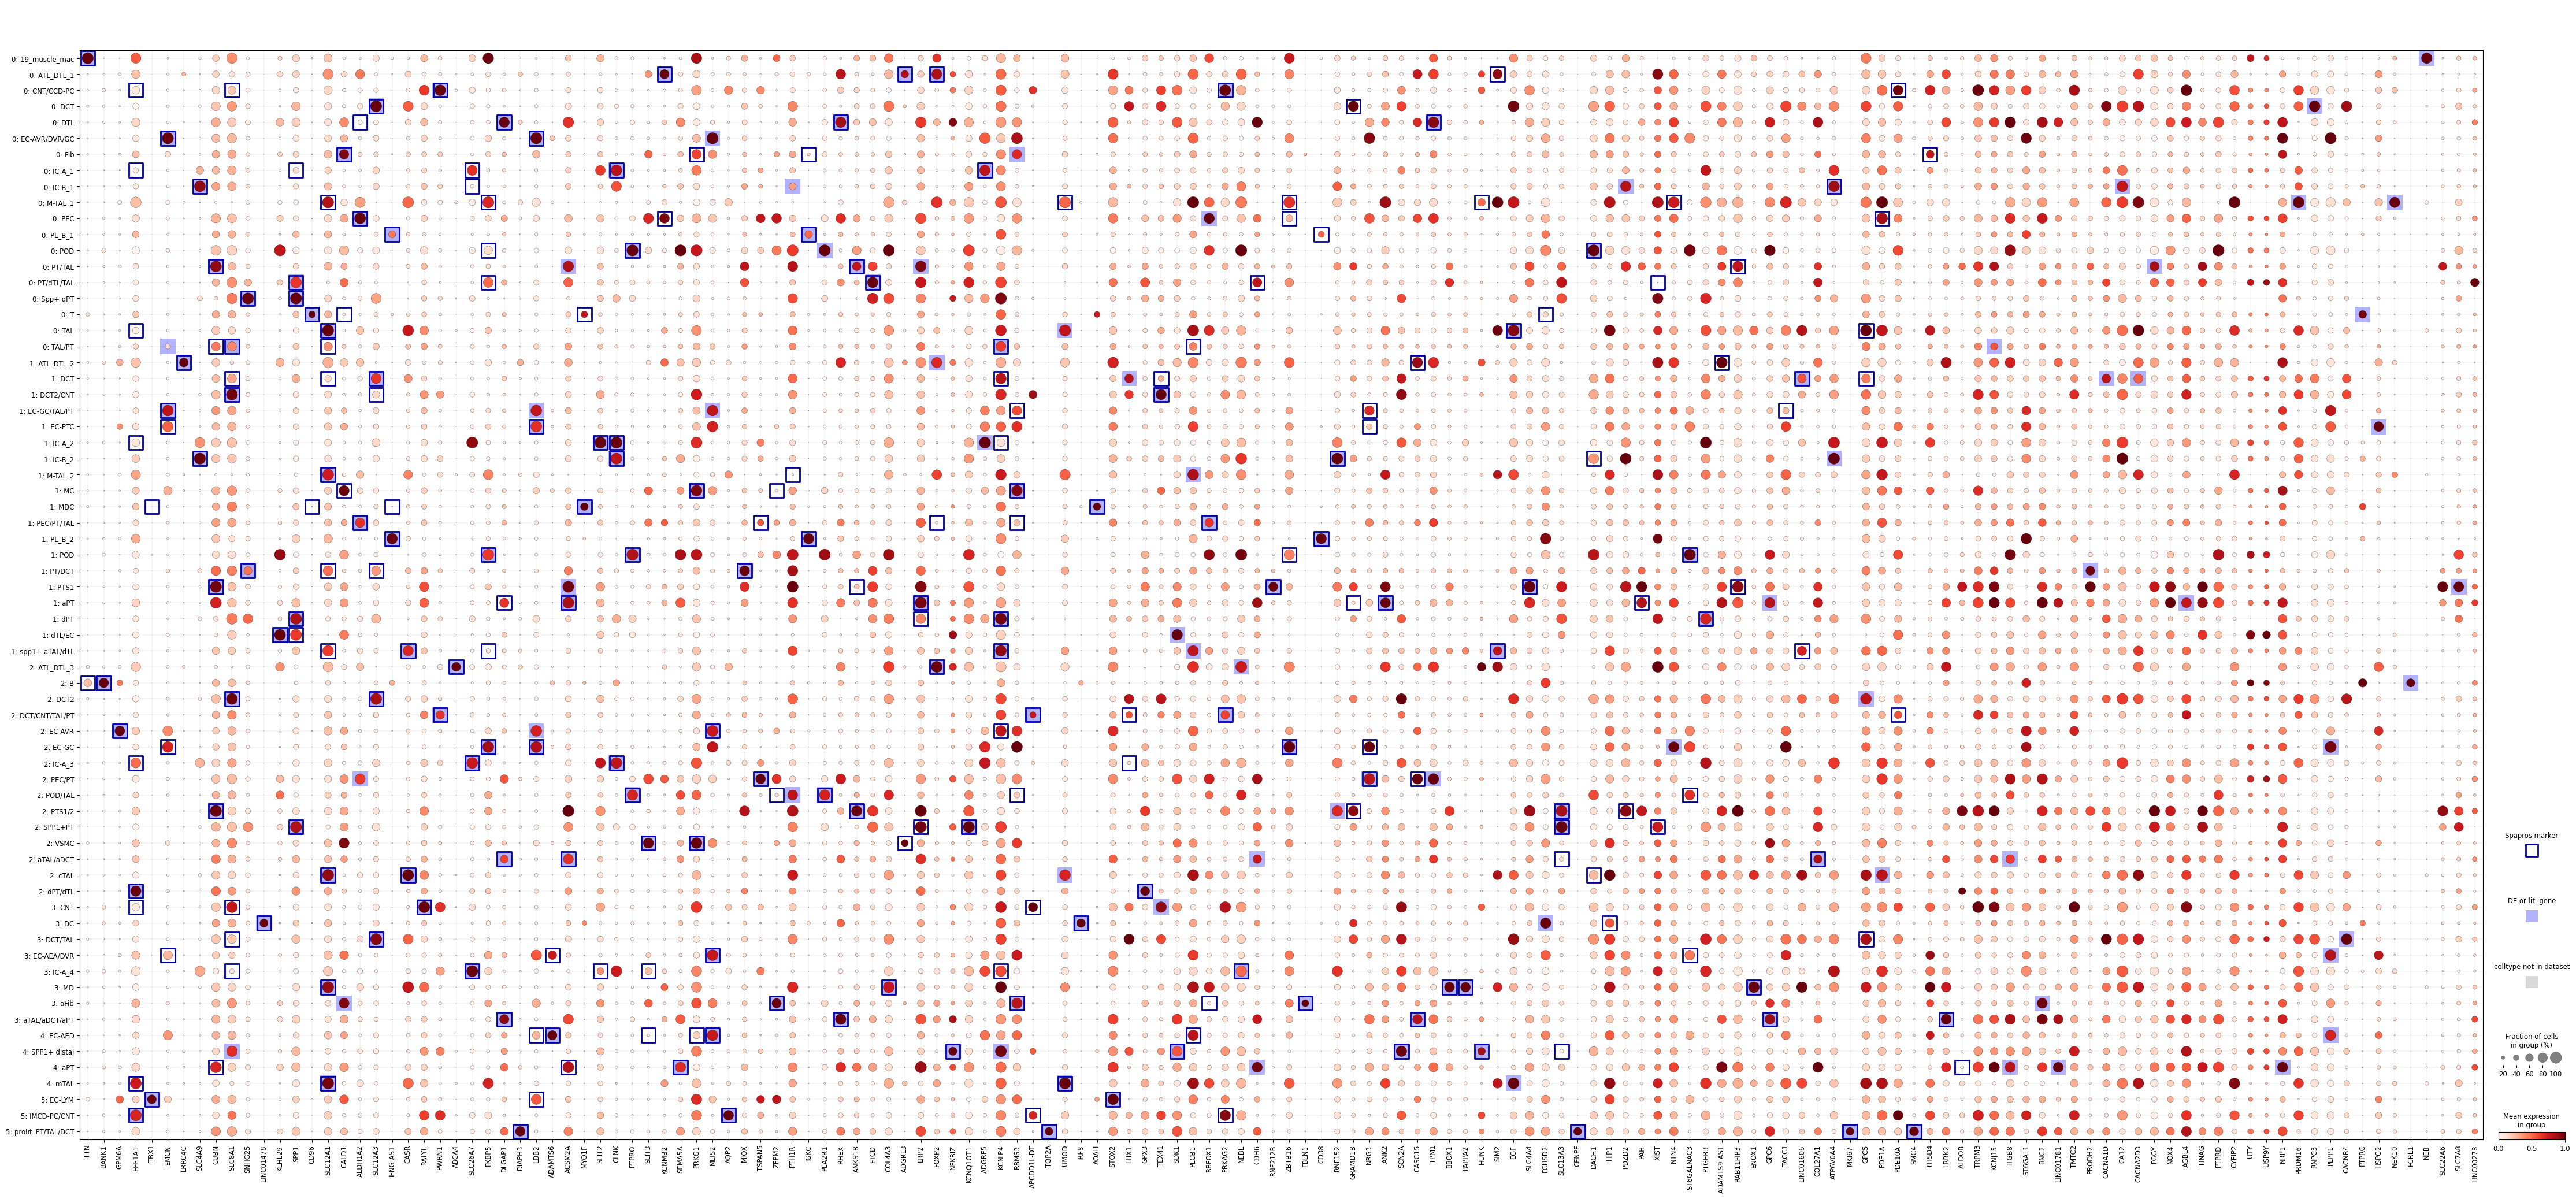

In [16]:
sp.pl.masked_dotplot(adata, selector, ct_key='subcluster')

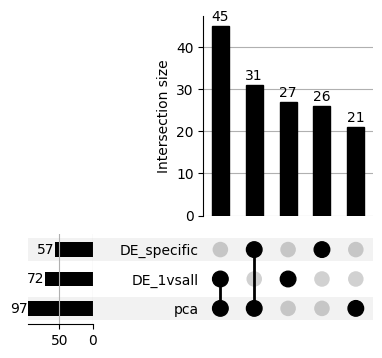

In [16]:
selector.plot_gene_overlap()

In [18]:
reference_sets = sp.se.select_reference_probesets(adata, obs_key='subcluster', n=150)

Output()

In [15]:
probeset = list(selector.probeset.index[selector.probeset.selection])

In [16]:
evaluator = sp.ev.ProbesetEvaluator(adata, celltype_key='subcluster', verbosity=1, results_dir='/rwthfs/rz/cluster/hpcwork/noco0013/projects/novo_postdoc/data/kidney_atlas/SpaPros/')

In [17]:
evaluator.evaluate_probeset(probeset, set_id="Spapros")

Output()

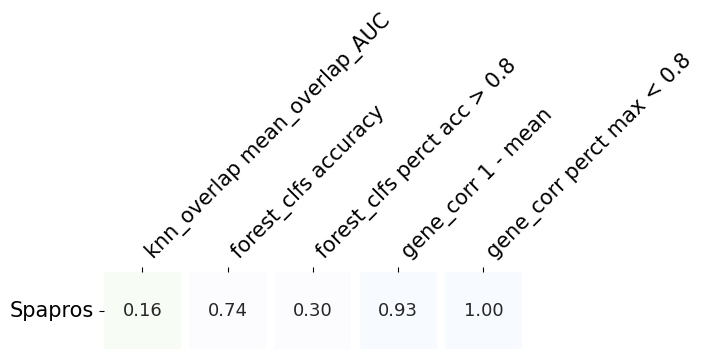

In [21]:
evaluator.plot_summary()

In [41]:
plt.figure(figsize=(50, 50))
evaluator.plot_confusion_matrix(fontsize=5, size_factor=20, save="Confusion_Matrix_Xenium_Panel_Kidney_Biopsy.pdf")

<Figure size 30000x30000 with 0 Axes>



In [42]:
evaluator.plot_coexpression()